# COMP-441L: NLP Lab — Text Similarity & Corpus Analysis
### Google Colab practical | Guided notebook + student exercises

**Topics:** corpus statistics, word frequencies, edit distance, n-grams, collocations

**Learning outcomes**
By the end of this practical, you should be able to:
- Explore a text corpus and calculate basic statistics.
- Find frequent words, n-grams, and collocations.
- Calculate edit distance between strings.

**How to use this notebook**
1. Open it in Google Colab.
2. Run cells from top to bottom (`Shift + Enter`).
3. Read the interpretation notes, not just the output.
4. Complete every **Your turn** exercise and write short answers in the designated Markdown cells.

> This notebook uses a small, built-in product-review corpus so everyone can run it without downloading a dataset. Small data is good for learning the methods, but corpus-level conclusions should be checked on a larger dataset.

## 0. Setup

We will use common Python NLP/data-science libraries. Run this cell once per fresh Colab runtime.

In [ ]:
%pip -q install rapidfuzz nltk scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from rapidfuzz import fuzz

text1 = "I love this phone"
text2 = "I like this mobile"

similarity = fuzz.ratio(text1, text2)

print("Text 1:", text1)
print("Text 2:", text2)
print("Similarity Score:", similarity)

Text 1: I love this phone
Text 2: I like this mobile
Similarity Score: 68.57142857142857


In [ ]:
import re
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

from rapidfuzz.distance import Levenshtein
from nltk.collocations import BigramCollocationFinder
from nltk.metrics import BigramAssocMeasures
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)
print("Setup complete. Ready for the lab!")

Setup complete. Ready for the lab!


## 1. Load and inspect a mini corpus

**Scenario:** An online store wants to understand customer reviews and identify similar or duplicate reviews.

First, inspect the data. Before applying NLP, always understand what one row represents, which columns exist, and whether any text is missing.

In [ ]:
data = [
    {"review_id": 1, "sentiment": "positive", "review_text": "This phone has excellent battery life"},
    {"review_id": 2, "sentiment": "positive", "review_text": "Excellent camera and excellent battery life"},
    {"review_id": 3, "sentiment": "positive", "review_text": "The phone has a great battery"},
    {"review_id": 4, "sentiment": "negative", "review_text": "Poor battery life and slow charging"},
    {"review_id": 5, "sentiment": "negative", "review_text": "The delivery was late and the package was damaged"},
    {"review_id": 6, "sentiment": "positive", "review_text": "The phone is good and the camera is excellent"},
    {"review_id": 7, "sentiment": "negative", "review_text": "Poor customer service and poor support"},
    {"review_id": 8, "sentiment": "positive", "review_text": "Battery life is good but charging is slow"},
    {"review_id": 9, "sentiment": "positive", "review_text": "Excellent phone, good camera, good battery"},
    {"review_id": 10, "sentiment": "negative", "review_text": "Customer support was slow and the service was poor"},
]

df = pd.DataFrame(data)
display(df)
print("Rows:", len(df))
print("Columns:", list(df.columns))
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_count"))
display(df.isna().sum())

,review_id,sentiment,review_text
0,1,positive,This phone has excellent battery life
1,2,positive,Excellent camera and excellent battery life
2,3,positive,The phone has a great battery
3,4,negative,Poor battery life and slow charging
4,5,negative,The delivery was late and the package was damaged
5,6,positive,The phone is good and the camera is excellent
6,7,negative,Poor customer service and poor support
7,8,positive,Battery life is good but charging is slow
8,9,positive,"Excellent phone, good camera, good battery"
9,10,negative,Customer support was slow and the service was poor


Rows: 10
Columns: ['review_id', 'sentiment', 'review_text']
Missing values per column:


,missing_count
review_id,0
sentiment,0
review_text,0


review_id      0
sentiment      0
review_text    0
dtype: int64

### Task 1A — Corpus statistics

Calculate:
- Total number of reviews
- Total number of tokens
- Average review length in words
- Shortest and longest review lengths

We will use a simple tokenizer. It converts text to lowercase and extracts alphabetic word sequences. This is a teaching baseline, not a universal tokenizer.

In [ ]:
def tokenize(text):
    return re.findall(r"\b[a-z]+\b", str(text).lower())

df["tokens"] = df["review_text"].apply(tokenize)
df["word_count"] = df["tokens"].apply(len)

all_tokens = []

for review_tokens in df["tokens"]:
    for word in review_tokens:
        all_tokens.append(word)



print("tokens:", all_tokens)
print("Number of reviews:", len(df))
print("Total tokens:", len(all_tokens))
print("Average words per review:", round(df["word_count"].mean(), 2))
print("Shortest review (words):", df["word_count"].min())
print("Longest review (words):", df["word_count"].max())

display(df[["review_id", "review_text", "word_count"]])

tokens: ['this', 'phone', 'has', 'excellent', 'battery', 'life', 'excellent', 'camera', 'and', 'excellent', 'battery', 'life', 'the', 'phone', 'has', 'a', 'great', 'battery', 'poor', 'battery', 'life', 'and', 'slow', 'charging', 'the', 'delivery', 'was', 'late', 'and', 'the', 'package', 'was', 'damaged', 'the', 'phone', 'is', 'good', 'and', 'the', 'camera', 'is', 'excellent', 'poor', 'customer', 'service', 'and', 'poor', 'support', 'battery', 'life', 'is', 'good', 'but', 'charging', 'is', 'slow', 'excellent', 'phone', 'good', 'camera', 'good', 'battery', 'customer', 'support', 'was', 'slow', 'and', 'the', 'service', 'was', 'poor']
Number of reviews: 10
Total tokens: 71
Average words per review: 7.1
Shortest review (words): 6
Longest review (words): 9


,review_id,review_text,word_count
0,1,This phone has excellent battery life,6
1,2,Excellent camera and excellent battery life,6
2,3,The phone has a great battery,6
3,4,Poor battery life and slow charging,6
4,5,The delivery was late and the package was damaged,9
5,6,The phone is good and the camera is excellent,9
6,7,Poor customer service and poor support,6
7,8,Battery life is good but charging is slow,8
8,9,"Excellent phone, good camera, good battery",6
9,10,Customer support was slow and the service was poor,9


### Your turn 1

1. Why is the average review length useful?
2. What might an unusually short review indicate?
3. This tokenizer removes punctuation and numbers. When could that be a problem?

###  Answers
1. The average (≈7.1 tokens) gives a baseline for the "typical" review size. It helps spot outliers and choose preprocessing/model settings (e.g., n-gram size, padding length).
2. A very short review carries little information, or may be spam, truncated, or an automated/placeholder entry. It can be unreliable for similarity or sentiment.
3. Dropping punctuation and numbers loses signal such as "5 stars", "$200", "iPhone 15" or emphatic "great!!!". It also splits contractions: "don't" becomes "don" and "t", which breaks negation handling.

## 2. Word frequencies

A frequency count tells us which words occur most often. It does **not** automatically tell us which words are most meaningful.

We will first count all words, then compare the result with a simple stop-word-filtered count.

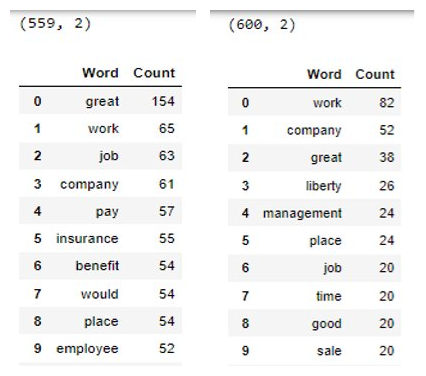

In [ ]:
word_counts = Counter(all_tokens)

print("Top 15 words (including common words):")
display(pd.DataFrame(
    word_counts.most_common(150),
    columns=["word", "frequency"]
))

Top 15 words (including common words):


,word,frequency
0,battery,6
1,and,6
2,the,6
3,excellent,5
4,phone,4
5,life,4
6,poor,4
7,was,4
8,is,4
9,good,4


Top 15 words (including common words):


,word,frequency
0,battery,6
1,and,6
2,the,6
3,excellent,5
4,phone,4
5,life,4
6,poor,4
7,was,4
8,is,4
9,good,4


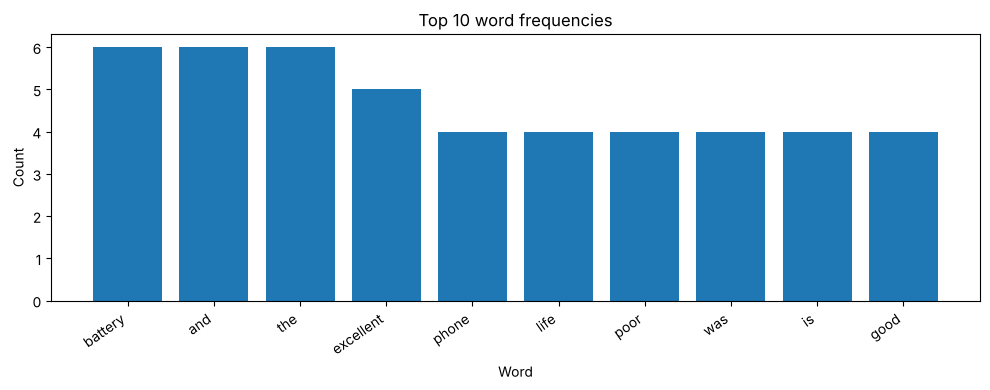

In [ ]:
word_counts = Counter(all_tokens)
print("Top 15 words (including common words):")
display(pd.DataFrame(word_counts.most_common(15), columns=["word", "frequency"]))

plt.figure(figsize=(10, 4))
top_words = word_counts.most_common(10)
plt.bar([w for w, _ in top_words], [c for _, c in top_words])
plt.title("Top 10 word frequencies")
plt.xlabel("Word")
plt.ylabel("Count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
stop_words = {
    "the", "and", "is", "a", "this", "was", "has", "but", "of", "in",
    "it", "to", "with", "for", "on", "very", "i", "my"
}
filtered_tokens = []

for word in all_tokens:
    if word not in stop_words:
        filtered_tokens.append(word)
filtered_counts = Counter(filtered_tokens)

print("Top 15 words after simple stop-word removal:")
display(pd.DataFrame(filtered_counts.most_common(15), columns=["word", "frequency"]))

Top 15 words after simple stop-word removal:


,word,frequency
0,battery,6
1,excellent,5
2,phone,4
3,life,4
4,poor,4
5,good,4
6,camera,3
7,slow,3
8,charging,2
9,customer,2


### Task 2B — Compare sentiment groups

Compare common words in positive and negative reviews. Notice that removing stop words can change the picture, and removing words such as **not** or **never** can destroy important meaning in some datasets.

In [ ]:
for label in ["positive", "negative"]:
    group_tokens = [
        word
        for _, row in df[df["sentiment"] == label].iterrows()
        for word in row["tokens"]
        if word not in stop_words
    ]
    print(f"\nTop words for {label} reviews:")
    display(pd.DataFrame(Counter(group_tokens).most_common(8),
                         columns=["word", "frequency"]))


Top words for positive reviews:


,word,frequency
0,excellent,5
1,battery,5
2,phone,4
3,good,4
4,life,3
5,camera,3
6,great,1
7,charging,1



Top words for negative reviews:


,word,frequency
0,poor,4
1,slow,2
2,customer,2
3,service,2
4,support,2
5,battery,1
6,life,1
7,charging,1


### Your turn 2

1. Which words are common in positive reviews?
2. Which words are common in negative reviews?
3. Why can raw frequency be misleading when comparing groups of different sizes?
4. Why should stop-word lists be chosen carefully?

### Answers
1. Positive reviews: *excellent* (5), *battery* (5), *phone* (4), *good* (4), *life* (3), *camera* (3).
2. Negative reviews: *poor* (4); *slow*, *customer*, *service*, *support* (2 each).
3. The groups differ in size (6 positive reviews / 41 tokens vs 4 negative / 30 tokens), so raw counts favour the larger group. Use relative frequency or log-odds instead.
4. Stop-word lists are domain-specific, and generic lists can remove meaningful words such as "not" or "never", which flips sentiment.

## 3. Edit distance

**Edit distance** measures the minimum number of character insertions, deletions, and substitutions required to transform one string into another.

Example: `machne` is likely a typo for `machine`.

We use RapidFuzz for a reliable implementation.
##Applications:  
Levenshtein Distance is widely used in:  
•	Spell checkers → suggest words close to the misspelled one  
•	Plagiarism detection → measure similarity between texts  
•	Natural Language Processing (NLP) → compare words, sentences, translations  
•	DNA sequence analysis → compare genetic strings  
•	Data de-duplication → find near-duplicate entries  


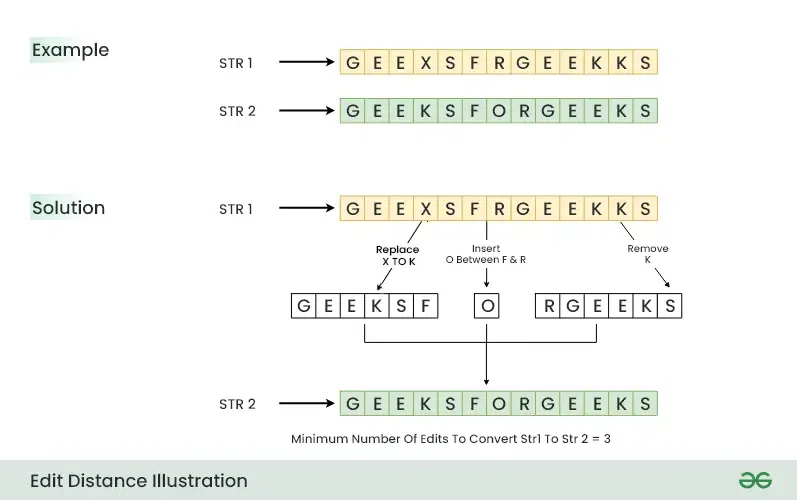

In [ ]:
word_pairs = [
    ("machine", "machne"),
    ("kitten", "sitting"),
    ("colour", "color"),
    ("good", "excellent"),
]

rows = []
for first, second in word_pairs:
    distance = Levenshtein.distance(first, second)
    similarity = Levenshtein.normalized_similarity(first, second)
    rows.append({
        "text_1": first,
        "text_2": second,
        "edit_distance": distance,
        "normalized_similarity": round(similarity, 3)
    })

display(pd.DataFrame(rows))

,text_1,text_2,edit_distance,normalized_similarity
0,machine,machne,1,0.857
1,kitten,sitting,3,0.571
2,colour,color,1,0.833
3,good,excellent,9,0.000


In [ ]:
def compute_levenshtein_distance(str1, str2):
    """Computes the Levenshtein distance between two strings using dynamic programming."""
    m, n = len(str1), len(str2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]

    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j

    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if str1[i-1] == str2[j-1] else 1
            dp[i][j] = min(
                dp[i-1][j] + 1,      # Deletion
                dp[i][j-1] + 1,      # Insertion
                dp[i-1][j-1] + cost  # Substitution
            )
    return dp[m][n]

def simple_spell_checker(misspelled_word, dictionary):
    """Suggests closest correct words from a dictionary using edit distance."""
    suggestions = []
    for word in dictionary:
        distance = compute_levenshtein_distance(misspelled_word, word)
        suggestions.append((word, distance))

    # Sort suggestions by minimum distance
    suggestions.sort(key=lambda x: x[1])
    return suggestions

# Test Task 01
dictionary_words = ["apple", "apply", "apples", "pineapple", "maple"]
misspelled_input = "appple"

print(f"Spell Checker Results for '{misspelled_input}':")
results = simple_spell_checker(misspelled_input, dictionary_words)
for word, dist in results:
    print(f"  - Correct word: '{word}' | Edit Distance: {dist}")

Spell Checker Results for 'appple':
  - Correct word: 'apple' | Edit Distance: 1
  - Correct word: 'apply' | Edit Distance: 2
  - Correct word: 'apples' | Edit Distance: 2
  - Correct word: 'maple' | Edit Distance: 3
  - Correct word: 'pineapple' | Edit Distance: 5


### Interpret the output

- A smaller edit distance means fewer character edits are needed.
- Normalized similarity is scaled from 0 to 1; 1 means identical strings.
- Character similarity is not the same as semantic similarity. `good` and `excellent` have related meanings but look different.

In [ ]:
# Try your own examples by changing the values below
word_a = "machine learning"
word_b = "machine learnng"

print("Edit distance:", Levenshtein.distance(word_a, word_b))
print("Normalized similarity:",
      round(Levenshtein.normalized_similarity(word_a, word_b), 3))

Edit distance: 1
Normalized similarity: 0.938


### Your turn 3

1. Which pair has the highest normalized similarity?
2. Why is edit distance useful for spelling correction?
3. Why is it not enough for comparing the meanings of full sentences?
4. Try three of your own word pairs.

###  Answers
1. machine / machne has the highest normalized similarity (0.857): a single deletion in a 7-letter word.
2. Typos are usually only a few character edits away from the intended word, so the closest dictionary word by edit distance is a good correction candidate.
3. It compares characters, not meaning. *good* vs *excellent* scores low despite similar meaning, while "not good" vs "good" is close in characters but opposite in meaning. Full sentences also need word order, synonyms and context.
4. My own pairs (verified by running the code):

| Pair | Edit distance | Normalized similarity |
|---|---|---|
| battery / batery | 1 | 0.857 |
| good / food | 1 | 0.75 |
| camera / cinema | 3 | 0.5 |

*good / food* is close in characters but unrelated in meaning.

## 4. N-grams: unigrams, bigrams, and trigrams

An **n-gram** is a sequence of *n* consecutive tokens:
- Unigram: one token (`battery`)
- Bigram: two tokens (`battery life`)
- Trigram: three tokens (`excellent battery life`)

N-grams help discover recurring phrases, but the result depends on tokenization and preprocessing.

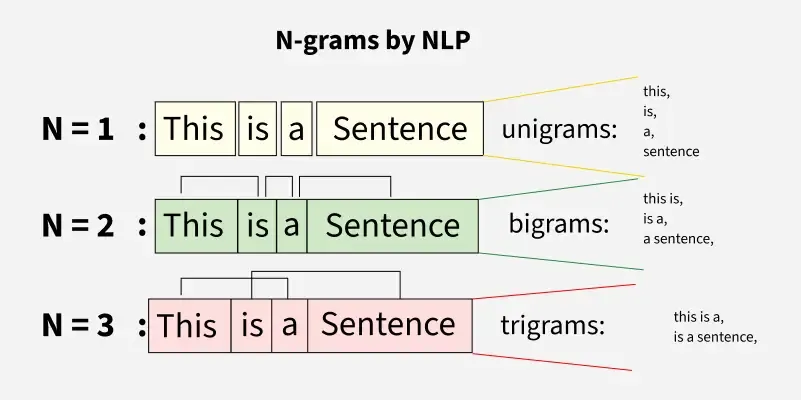

In [ ]:
from nltk.util import ngrams

def ngram_counts(tokens, n):
    return Counter(ngrams(tokens, n))

for n in (1, 2, 3):
    counts = ngram_counts(all_tokens, n)
    rows = [(" ".join(gram), count) for gram, count in counts.most_common(10)]
    print(f"Top {n}-grams:")
    display(pd.DataFrame(rows, columns=["ngram", "frequency"]))

Top 1-grams:


,ngram,frequency
0,battery,6
1,and,6
2,the,6
3,excellent,5
4,phone,4
5,life,4
6,poor,4
7,was,4
8,is,4
9,good,4


Top 2-grams:


,ngram,frequency
0,battery life,4
1,and the,3
2,phone has,2
3,excellent battery,2
4,the phone,2
5,is good,2
6,this phone,1
7,has excellent,1
8,life excellent,1
9,excellent camera,1


Top 3-grams:


,ngram,frequency
0,excellent battery life,2
1,this phone has,1
2,phone has excellent,1
3,has excellent battery,1
4,battery life excellent,1
5,life excellent camera,1
6,excellent camera and,1
7,camera and excellent,1
8,and excellent battery,1
9,battery life the,1


### Your turn 4

1. Find the most frequent bigram in this corpus.
2. Which trigram might describe a product feature?
3. Why might `battery life` be more informative than `battery` alone?
4. What happens to phrase counts if stop words are removed **before** generating n-grams? Does that preserve the original phrases?

### Answers
1. The most frequent bigram is "battery life" (4 occurrences).
2. "excellent battery life" (2 occurrences) describes a product feature.
3. "battery life" names a specific aspect of the product, whereas "battery" alone is ambiguous (capacity, charging, drain...).
4. No. Removing stop words first creates false adjacency (e.g., "good charging" from "good but charging"), so the original phrases are not preserved. Generate n-grams first, then filter.

## 5. Collocations

A **collocation** is a word combination that occurs together more strongly than expected by chance. Examples in English include `customer service` and `credit card`.

We will compare:
- Raw frequency: how many times a pair appears
- Pointwise mutual information (PMI): how strongly a pair is associated relative to the individual words

PMI can overvalue rare pairs, so frequency thresholds and careful interpretation matter. This small corpus is for learning the method, not for making general claims about language.

\[
PMI(x,y)=\log_2\left(\frac{P(x,y)}{P(x)P(y)}\right)
\]

Where:
- \(P(x,y)\) = probability of the two words occurring together as a bigram.
- \(P(x)\) = probability of the first word.
- \(P(y)\) = probability of the second word.
You don't need to calculate these probabilities manually; NLTK does that for you.

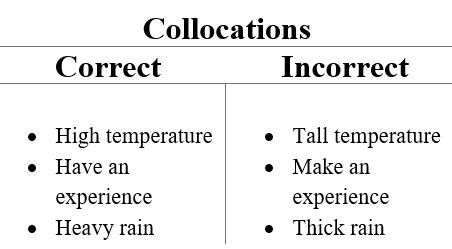

In [ ]:
finder = BigramCollocationFinder.from_words(all_tokens)

# Keep pairs that occur at least twice to reduce one-off pairs in this toy corpus.
finder.apply_freq_filter(2)

print("Top bigrams by frequency:")
display(pd.DataFrame(
    [(" ".join(pair), count) for pair, count in finder.ngram_fd.most_common(10)],
    columns=["bigram", "frequency"]
))

print("Top bigrams by PMI:")
pmi_results = finder.score_ngrams(BigramAssocMeasures.pmi)
display(pd.DataFrame(
    [(" ".join(pair), round(score, 3)) for pair, score in pmi_results[:10]],
    columns=["bigram", "PMI"]
))

Top bigrams by frequency:


,bigram,frequency
0,battery life,4
1,and the,3
2,phone has,2
3,excellent battery,2
4,the phone,2
5,is good,2


Top bigrams by PMI:


,bigram,PMI
0,phone has,4.150
1,battery life,3.565
2,is good,3.150
3,and the,2.565
4,the phone,2.565
5,excellent battery,2.243


### Your turn 5

1. Do the most frequent pairs also have the highest PMI?
2. Why might PMI rank a pair highly even if it is not common?
3. How could you make collocation results more reliable on a larger dataset?
4. Give two examples of collocations from a domain you know (e.g., health, education, computing).

###  Answers
1. Only partly. "battery life" is high on both lists, but the PMI ranking is topped by rarer pairs such as "phone has" (PMI 4.150) with a lower count.
2. PMI divides by P(x)·P(y), so rare words that always occur together get a very high score even with few observations.
3. Use a larger corpus, raise the frequency threshold, use measures such as log-likelihood, chi-square or t-test, and add POS filters (e.g., adjective+noun).
4. Examples: Health: "blood pressure", "heart attack". Computing: "machine learning", "operating system". Education: "lesson plan", "learning outcomes".

## 6. Final reflection and viva questions

Answer these in your own words:

1. What is the difference between corpus statistics and text similarity?
2. How does edit distance differ from cosine similarity?
3. What is the difference between a bigram and a collocation?
4. Why can frequent words be less informative than less frequent words?
5. What are two limitations of TF-IDF cosine similarity?
6. When might character n-grams be helpful?
7. Why should we test similarity thresholds on labelled examples?
8. How could semantic embeddings improve this pipeline?

###  Answers
1. Corpus statistics describe the whole collection (size, vocabulary, frequencies); text similarity compares individual texts with each other.
2. Edit distance works on characters and is order-sensitive; cosine similarity works on word-weight vectors (e.g., TF-IDF) and ignores word order.
3. A bigram is any two consecutive tokens; a collocation is a pair that co-occurs more often than chance would predict.
4. Very frequent words appear everywhere and don't discriminate between documents; this is what IDF captures.
5. TF-IDF cosine has no word order or negation handling ("good, not bad" vs "bad, not good"), and no semantics (synonyms look different).
6. Character n-grams help with typos, short text, product codes/names and languages without clear word boundaries.
7. Good thresholds depend on the dataset and text type, so test them on labelled duplicate / non-duplicate pairs.
8. Embeddings capture synonyms, paraphrase and context, so similar meanings score high even with no shared words.

### Submission checklist

- [x] All code cells run successfully.
- [x] All **Your turn** sections have answers.
- [ ] The mini-project output is included (not part of this notebook; add one if your instructor requires it).
- [ ] At least one failure case and one improvement are explained (see Your turn 3 Q3 and Your turn 4 Q4 for examples).

**Instructor note:** The built-in corpus is intentionally small and illustrative. For an assessed extension, provide a larger, appropriately licensed corpus and ask students to compare findings across datasets.